# Image Segmentation with K-means

![](img/banner.png)

Computer Science Dept, Ferdowsi University of Mashhad

## What "segmentation" means

An image is a table of numbers. A gray image is an `H x W` array with one
brightness value per pixel; a colour image has three numbers per pixel. The
**segmentation** of an image is a *label* for every pixel saying which region,
or which object, that pixel belongs to. Segmentation therefore does not change
the picture, it changes how we *describe* it: instead of 240,000 gray levels we
end up with a handful of regions.

Two ways of finding those labels are compared in this page:

1. **Thresholding** — a cut value chosen by hand: pixels above it are one
   region, the rest are another.
2. **Clustering** — the cut is *learned* from the data by
   [K-means](High-Dimensional-Data-and-K-Means.ipynb), and it generalises to
   more than two regions without anybody writing a threshold down.

The third step adds the missing ingredient of the first two: the **position** of
the pixel. A brightness-only method cannot tell two equally bright regions
apart, however far apart they are in the picture.

### What you should be able to do at the end

* turn an image into the `(n_pixels, n_features)` table that scikit-learn
  expects, and explain why passing the raw image to `fit` is the wrong shape;
* read `labels_` and `cluster_centers_` and say which of the two paints the
  picture, and why;
* add coordinates as extra features and predict what changes;
* explain why cluster numbers have to be reordered before two segmentations can
  be compared.

### The tools

Four libraries are enough: NumPy for the arrays, matplotlib to look at them,
`KMeans` from scikit-learn, and `skimage` for the sample photograph used in the
second half.

In [1]:
# Importing Necessary Libraries
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage import data
from skimage.color import rgb2gray
from skimage.transform import resize

%matplotlib inline

## 1. A toy image

Real photographs are large and their histograms are smooth, which hides what the
algorithm actually does. So the first example is a `5 x 6` array of small
integers, chosen so that every number can be read by eye. Think of each entry as
a gray level: `0` is black and `9` is white.

A fixed random seed (`default_rng(0)`) is used so that the numbers — and
therefore every figure in this section — are the same each time the page is
built.

In [2]:
# A 5 x 6 image with integer gray levels from 0 (black) to 9 (white)
rng = np.random.default_rng(0)
img = rng.integers(10, size=(5, 6))
img

array([[8, 6, 5, 2, 3, 0],
       [0, 0, 1, 8, 6, 9],
       [5, 6, 9, 7, 6, 5],
       [5, 9, 2, 8, 6, 0],
       [3, 8, 5, 0, 7, 7]])

`imshow` draws the array as a picture, but the *scale* of the colours has to be
stated: without `vmin` and `vmax` matplotlib rescales the colormap to whatever
range happens to be in the data, and two images of the same scene can then look
different. Here the scale is fixed to the full range `0..9`.

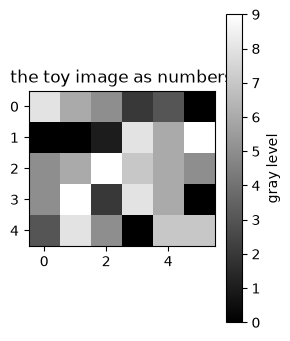

In [3]:
plt.figure(figsize=(3, 4))
plt.imshow(img, cmap=plt.cm.gray, vmin=0, vmax=9)
plt.colorbar(label="gray level")
plt.title("the toy image as numbers");

## 2. The simplest segmentation: thresholding

Pick a number, say `5`, and call every pixel above it *foreground*:

$$
\text{label}(i,j) =
\begin{cases}
1 & \text{if } \mathrm{img}[i,j] > 5,\\
0 & \text{otherwise.}
\end{cases}
$$

In NumPy this is a single comparison. The result is a Boolean array with the same
shape as the image, and `True`/`False` behave exactly like `1`/`0`, which is why
a two-region segmentation is a *binary* image.

In [4]:
seg_img = img > 5
type(seg_img), seg_img

(numpy.ndarray,
 array([[ True,  True, False, False, False, False],
        [False, False, False,  True,  True,  True],
        [False,  True,  True,  True,  True, False],
        [False,  True, False,  True,  True, False],
        [False,  True, False, False,  True,  True]]))

The segmentation is the mask, not the numbers. To see it, put the two arrays side
by side on **their own scales**: `0..9` for the original so that the gray levels
mean what they meant, and `0..1` for the mask so that black really is label `0`.

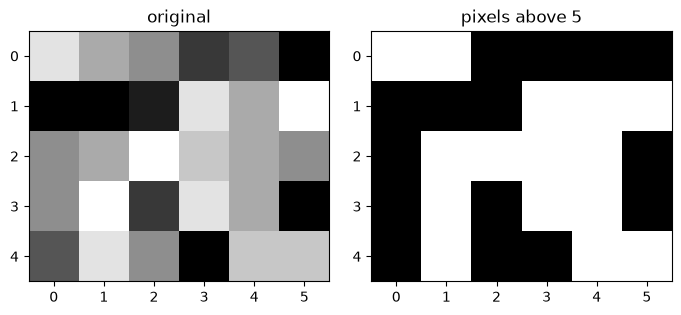

In [5]:
fig = plt.figure(figsize=(7, 3))
fig.add_subplot(1, 2, 1)
plt.imshow(img, cmap=plt.cm.gray, vmin=0, vmax=9)
plt.title("original")

fig.add_subplot(1, 2, 2)
plt.imshow(seg_img, cmap=plt.cm.gray, vmin=0, vmax=1)
plt.title("pixels above 5")

plt.tight_layout();

### Where thresholding stops

Three things go wrong as soon as the image is a photograph rather than a toy:

* **The cut is invented.** Why `5` and not `4` or `6`? On this toy array the
  answer barely matters; on a real image every choice gives a different area,
  and nobody knows which one is right.
* **One cut cannot survive uneven lighting.** A shadowed white cup and a lit dark
  table can have the same gray level, so no single number separates "cup" from
  "table" everywhere in the image.
* **There may be more than two regions.** A third region needs a second
  hand-chosen cut, a fourth needs a third, and the cuts are no longer independent
  of each other.

Clustering replaces the invented cut by one estimated from the data: we say only
*how many* groups we want, `K`, and K-means finds where the groups are.

## 3. K-means on one feature at a time

K-means partitions the samples into `K` groups by alternating two steps:

1. **assign** every sample to the nearest center,
2. **update** every center to the average of the samples assigned to it,

until nothing moves. The `KMeans` class from scikit-learn does the whole thing in
`.fit(X)`, and leaves two results behind:

| attribute | shape | meaning |
|---|---|---|
| `labels_` | `(n_samples,)` | which group each sample landed in: `0`, `1`, …, `K-1` |
| `cluster_centers_` | `(K, n_features)` | the average of each group |

### The shape K-means expects

`KMeans` knows nothing about images. It receives a table with **one sample per
row** and **one feature per column**:

```
X.shape == (n_samples, n_features)
```

A list of seven numbers is therefore *not* a valid table: it is a single sample
with seven features, which is a different problem. `reshape(-1, 1)` turns the
seven numbers into seven rows of one column each, and `-1` means *"work out this
dimension yourself"*.

In [6]:
integer_array = np.array([1, 2, 3, 7, 8, 9, 10])
X = integer_array.reshape(-1, 1)   # 7 samples, 1 feature each

kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
kmeans.fit(X)

labels = kmeans.labels_
cluster_centers = kmeans.cluster_centers_.ravel()

print("X.shape        :", X.shape)
print("labels         :", labels)
print("cluster centers:", cluster_centers)

X.shape        : (7, 1)
labels         : [1 1 1 0 0 0 0]
cluster centers: [8.5 2. ]


Two notes on the output.

* The labels are `0` and `1`, but nothing says that `0` is the darker group.
  Cluster numbers are **arbitrary names**; here it happens to come out in one
  order, and in another run of another data set it may be reversed.
* The centers are the *averages*, not members: the data contains `2` and `7`,
  the centers are `2.0` and `8.0`. That is the "learned cut" — everything below
  `5` belongs to the first group, everything above to the second.

### The trap: fitting the image itself

Now the same call on the toy image. `img` has shape `5 x 6`, so scikit-learn reads
it as **5 samples with 6 features each** — five rows of six numbers — and returns
five labels, one per *row*. The result is a grouping of horizontal lines, not a
segmentation of pixels.

In [7]:
kmeans_wrong = KMeans(n_clusters=2, n_init=10, random_state=0)
kmeans_wrong.fit(img)          # img is 5 x 6, not 30 x 1

print("features K-means read:", kmeans_wrong.n_features_in_)
print("number of labels     :", len(kmeans_wrong.labels_))
print("labels               :", kmeans_wrong.labels_)

features K-means read: 6
number of labels     : 5
labels               : [0 1 0 0 0]


The fix is to say explicitly what a sample is: **one pixel, one gray level**.
Flattening the image into `(H*W, 1)` gives 30 samples with a single feature, and
then the two groups are "dark pixels" and "bright pixels" — exactly what
thresholding computed, except that the cut was learned instead of typed in.

In [8]:
X = img.reshape(-1, 1)          # 30 pixels, one gray value each
print("X.shape:", X.shape)

kmeans = KMeans(n_clusters=2, n_init=10, random_state=0)
kmeans.fit(X)

labels = kmeans.labels_
cluster_centers = kmeans.cluster_centers_.ravel()

print("labels :", labels)
print("centers:", np.sort(cluster_centers))

X.shape: (30, 1)
labels : [0 0 0 1 1 1 1 1 1 0 0 0 0 0 0 0 0 0 0 0 1 0 0 1 1 0 0 1 0 0]
centers: [1.1  6.75]


### Putting the labels back

`labels` is a flat list in *row-major* order: the first `W` entries are the first
row of the image, the next `W` the second row, and so on — the same order in
which `reshape(-1, 1)` read the pixels. Reshaping to `img.shape` therefore puts
every label back on its own pixel.

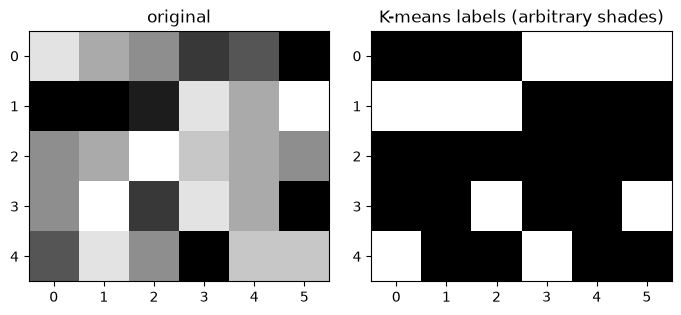

In [9]:
seg_img_labels = labels.reshape(img.shape)   # back to 5 x 6

fig = plt.figure(figsize=(7, 3))
fig.add_subplot(1, 2, 1)
plt.imshow(img, cmap=plt.cm.gray, vmin=0, vmax=9)
plt.title("original")

fig.add_subplot(1, 2, 2)
plt.imshow(seg_img_labels, cmap=plt.cm.gray, vmin=0, vmax=1)
plt.title("K-means labels (arbitrary shades)")

plt.tight_layout();

### Labels are names; centers are gray levels

The right panel shows the *labels*, and it looks like a segmentation — but the
colours it uses are cluster ids `0` and `1`, not brightness. If the labels had
come out the other way round, the same regions would have been painted in swapped
shades, which makes two segmentations impossible to compare.

Painting each pixel with the **center** of its cluster repairs this. The image is
then *posterised*: every region gets one gray level, and those levels are the true
average brightness of the region, so an ordering exists.

In [10]:
print("label -> learned gray level:",
      {k: round(float(c), 2) for k, c in enumerate(cluster_centers)})

# replace every pixel by the center of the cluster it belongs to
seg_img_centers = cluster_centers[labels].reshape(img.shape)

label -> learned gray level: {0: 6.75, 1: 1.1}


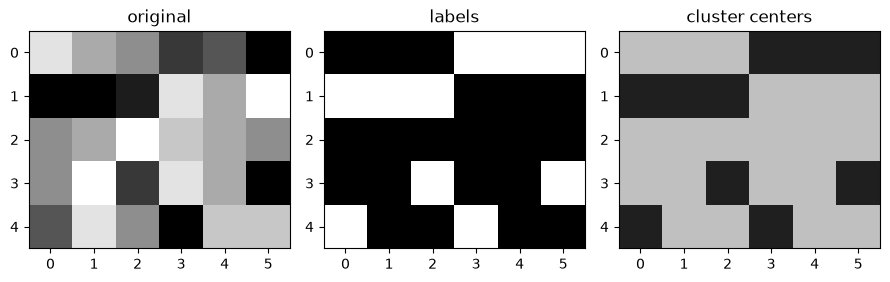

In [11]:
fig = plt.figure(figsize=(9, 3))
fig.add_subplot(1, 3, 1)
plt.imshow(img, cmap=plt.cm.gray, vmin=0, vmax=9)
plt.title("original")

fig.add_subplot(1, 3, 2)
plt.imshow(seg_img_labels, cmap=plt.cm.gray, vmin=0, vmax=1)
plt.title("labels")

fig.add_subplot(1, 3, 3)
plt.imshow(seg_img_centers, cmap=plt.cm.gray, vmin=0, vmax=9)
plt.title("cluster centers")

plt.tight_layout();

## 4. A real photograph

`skimage.data` ships a few test images; the one used here is a `400 x 600` colour
picture of a coffee cup. `rgb2gray` converts it with the usual weighted average of
the three channels, so a pixel becomes a single number in `[0, 1]`. Working in
gray first keeps the feature space one-dimensional, which makes what K-means does
easy to read; clustering in colour is one of the exercises.

colour image: (400, 600, 3) uint8
gray image  : (400, 600) 0.0002827450980392157 1.0


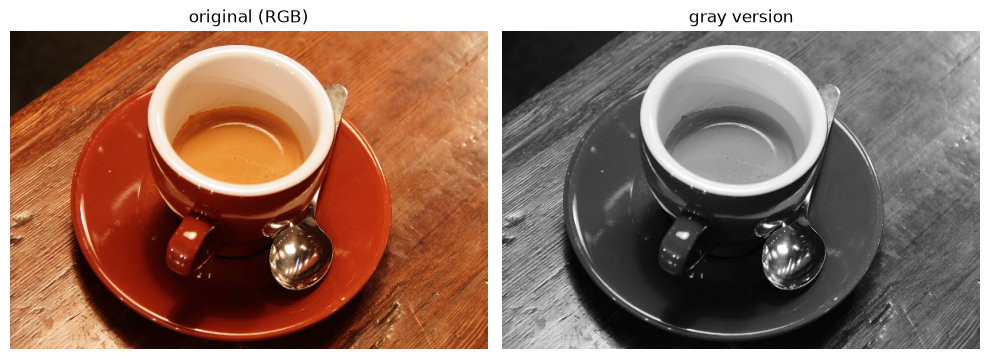

In [12]:
coffee = data.coffee()
gray_coffee = rgb2gray(coffee)      # colour -> gray, values in [0, 1]

print("colour image:", coffee.shape, coffee.dtype)
print("gray image  :", gray_coffee.shape, gray_coffee.min(), gray_coffee.max())

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(coffee); axes[0].set_title("original (RGB)")
axes[1].imshow(gray_coffee, cmap="gray"); axes[1].set_title("gray version")
for a in axes:
    a.axis("off")
plt.tight_layout();

`K = 4` asks for four brightness groups: typically the dark table, the mid-tone
plate, the bright cup, and the highlight on the cup. Nothing in the code knows
about cups or tables — the pixels are sorted by their gray level alone, and the
picture is painted afterwards.

number of pixels   : 240000
learned gray levels: [0.088 0.312 0.522 0.804]


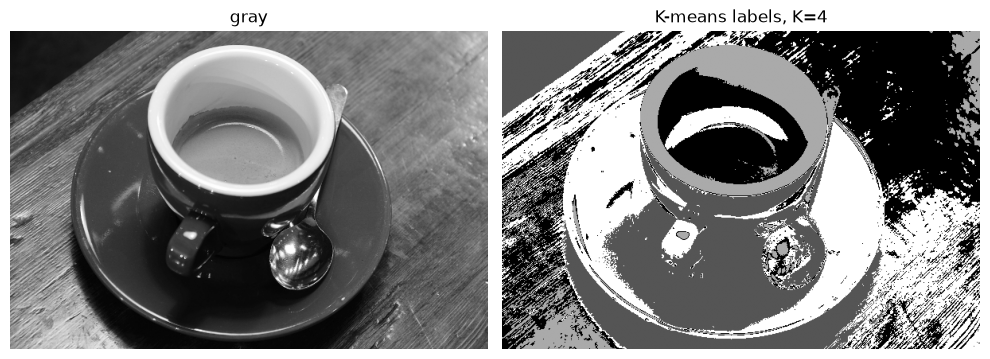

In [13]:
X = gray_coffee.reshape(-1, 1)      # one feature per pixel: its gray level
K = 4
kmeans = KMeans(n_clusters=K, n_init=10, random_state=0)
labels = kmeans.fit(X).labels_
cluster_centers = kmeans.cluster_centers_.ravel()

print("number of pixels   :", X.shape[0])
print("learned gray levels:", np.round(np.sort(cluster_centers), 3))

seg_img_labels = labels.reshape(gray_coffee.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(gray_coffee, cmap="gray"); axes[0].set_title("gray")
axes[1].imshow(seg_img_labels, cmap="gray")
axes[1].set_title(f"K-means labels, K={K}")
for a in axes:
    a.axis("off")
plt.tight_layout();

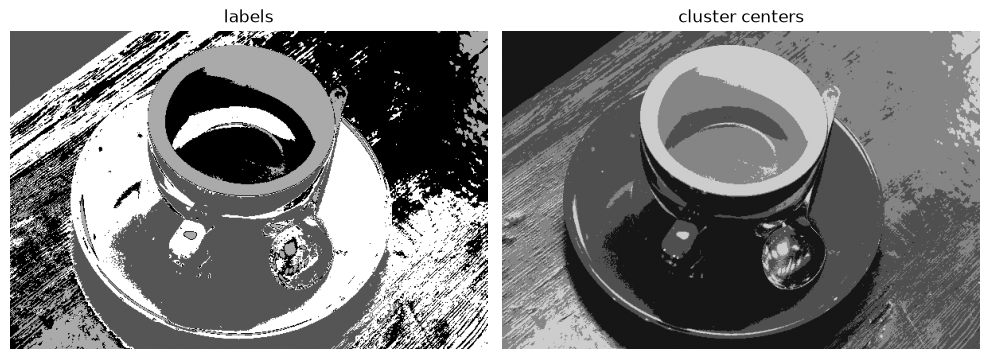

In [14]:
# paint every pixel with the gray level of its cluster center
seg_img_centers = cluster_centers[labels].reshape(gray_coffee.shape)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].imshow(seg_img_labels, cmap="gray"); axes[0].set_title("labels")
axes[1].imshow(seg_img_centers, cmap="gray", vmin=0, vmax=1)
axes[1].set_title("cluster centers")
for a in axes:
    a.axis("off")
plt.tight_layout();

### Choosing K

`K` is the only number the user supplies, and it is a statement about the scene,
not about the algorithm: "I believe there are four kinds of surface here". Too
small and two different surfaces share a region; too large and one surface is
split into shades of itself. The usual diagnostics — the elbow of the inertia,
the silhouette score — are the subject of the
[clustering validation page](Clustering-Validation-Metrics.ipynb).

## 5. Pixel positions as extra features

Everything above looked at one pixel at a time. Flattening the image threw away
the only thing that said *where* a pixel was: two pixels with the same gray level
are the same sample to K-means, whether they sit next to each other or at
opposite corners. So a method that uses brightness only can never separate two
parts of an object that happen to have the same colour, and it happily paints
scattered islands of one region inside another.

The repair is to give every pixel **three** features instead of one: its gray
level `v`, its column `x` and its row `y`. K-means then clusters points in 3-D,
and two pixels must agree in brightness *and* be close in space to share a
region.

### Scale matters

The gray level lives in `[0, 1]`, while a column index runs up to `w - 1` — a few
hundred. Euclidean distance is dominated by the largest numbers, so with raw
coordinates the brightness would be ignored and the result would be a tiling of
the image into equal squares. Dividing every column by its maximum puts all three
features on a `[0, 1]` scale, where they can compete.

In [15]:
coffee_small = resize(coffee, (coffee.shape[0] // 2, coffee.shape[1] // 2),
                      anti_aliasing=True)
gray_small = rgb2gray(coffee_small)
h, w = gray_small.shape
print("image size:", gray_small.shape, "-> pixels:", h * w)

# feature 1: the gray level of each pixel
X_intensity = gray_small.reshape(-1, 1)

image size: (200, 300) -> pixels: 60000


In [16]:
# features 2 and 3: the column and the row of each pixel
xx, yy = np.meshgrid(np.arange(w), np.arange(h))
coords = np.column_stack([xx.ravel(), yy.ravel()])
print("coordinates of the first three pixels:\n", coords[:3])

X_xy = np.concatenate([X_intensity, coords], axis=1)
print("min / max of each feature before scaling:\n",
      np.vstack([X_xy.min(axis=0), X_xy.max(axis=0)]))

# put every column on a [0, 1] scale, so no feature wins by its units
X_xy = X_xy / X_xy.max(axis=0)
print("after scaling:\n", np.round(X_xy[:3], 3))

coordinates of the first three pixels:
 [[0 0]
 [1 0]
 [2 0]]
min / max of each feature before scaling:
 [[1.48394732e-02 0.00000000e+00 0.00000000e+00]
 [9.94999902e-01 2.99000000e+02 1.99000000e+02]]
after scaling:
 [[0.057 0.    0.   ]
 [0.057 0.003 0.   ]
 [0.059 0.007 0.   ]]


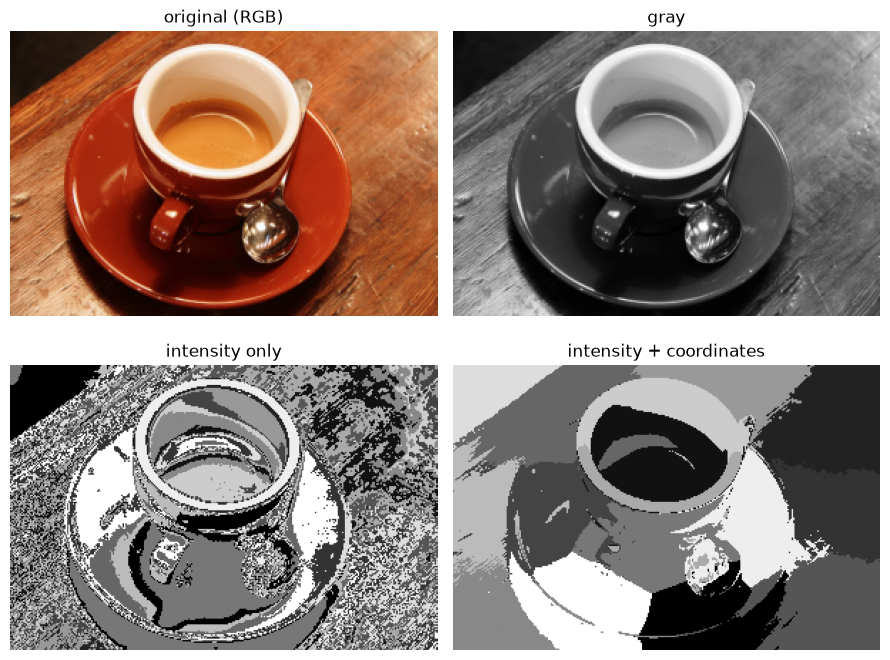

In [17]:
K = 16
labels_int = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_intensity).labels_
labels_xy = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X_xy).labels_

seg_int = labels_int.reshape(gray_small.shape)
seg_xy = labels_xy.reshape(gray_small.shape)

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
axes[0, 0].imshow(coffee_small); axes[0, 0].set_title("original (RGB)")
axes[0, 1].imshow(gray_small, cmap="gray"); axes[0, 1].set_title("gray")
axes[1, 0].imshow(seg_int, cmap="gray"); axes[1, 0].set_title("intensity only")
axes[1, 1].imshow(seg_xy, cmap="gray"); axes[1, 1].set_title("intensity + coordinates")
for a in axes.ravel():
    a.axis("off")
plt.tight_layout();

The difference is visible immediately: with coordinates the regions follow the
outline of the cup, and the scattered bright specks of the intensity-only result
disappear, because a speck is now close to a real region in space or it is not.

Two remarks before going on.

* With coordinates, the distance mixes *brightness difference* and *spatial
  distance*, and the normalisation decides the exchange rate. Rescaling the
  coordinate columns by a factor `\lambda < 1` weakens the spatial term and makes
  the result look more like the intensity-only version, which is the continuous
  knob between the two extremes shown above.
* The third and fourth panels are painted with cluster **ids**, so their shades
  are arbitrary. Comparing them fairly needs the step below.

### Reordering the labels by brightness

Cluster `0` in one segmentation and cluster `0` in another have nothing in common:
the numbering depends on where the centers happened to start. To compare two
segmentations — and even to look at one — number the clusters by the average gray
level of their pixels, so that `0` is always the darkest region and `K-1` the
brightest. `np.argsort` gives the ranking, and the loop below applies that
ranking to the labels.

In [18]:
def relabel_by_brightness(labels, pixels, K):
    """Number the clusters from the darkest (0) to the brightest (K - 1)."""
    mean_level = np.array([pixels[labels == k].mean() for k in range(K)])
    order = np.argsort(mean_level)          # order[rank] = old cluster id
    new_labels = np.zeros_like(labels)
    for k in range(K):
        new_labels[labels == k] = np.where(order == k)[0][0]
    return new_labels, mean_level[order]

In [19]:
pixels = gray_small.ravel()

new_labels_int, levels_int = relabel_by_brightness(labels_int, pixels, K)
new_labels_xy, levels_xy = relabel_by_brightness(labels_xy, pixels, K)

print("intensity only :", np.round(levels_int, 3))
print("intensity + xy :", np.round(levels_xy, 3))

intensity only : [0.043 0.095 0.154 0.213 0.269 0.313 0.364 0.415 0.466 0.516 0.574 0.628
 0.691 0.76  0.851 0.935]
intensity + xy : [0.091 0.101 0.105 0.124 0.254 0.294 0.362 0.377 0.444 0.468 0.493 0.558
 0.57  0.642 0.814 0.885]


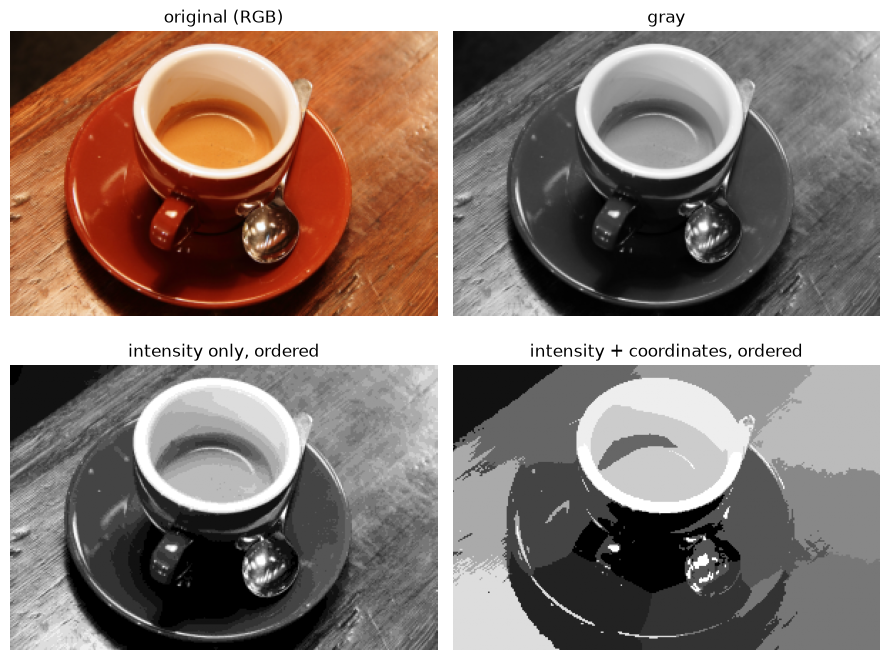

In [20]:
seg_int = new_labels_int.reshape(gray_small.shape)
seg_xy = new_labels_xy.reshape(gray_small.shape)

fig, axes = plt.subplots(2, 2, figsize=(9, 7))
axes[0, 0].imshow(coffee_small); axes[0, 0].set_title("original (RGB)")
axes[0, 1].imshow(gray_small, cmap="gray"); axes[0, 1].set_title("gray")
axes[1, 0].imshow(seg_int, cmap="gray", vmin=0, vmax=K - 1)
axes[1, 0].set_title("intensity only, ordered")
axes[1, 1].imshow(seg_xy, cmap="gray", vmin=0, vmax=K - 1)
axes[1, 1].set_title("intensity + coordinates, ordered")
for a in axes.ravel():
    a.axis("off")
plt.tight_layout();

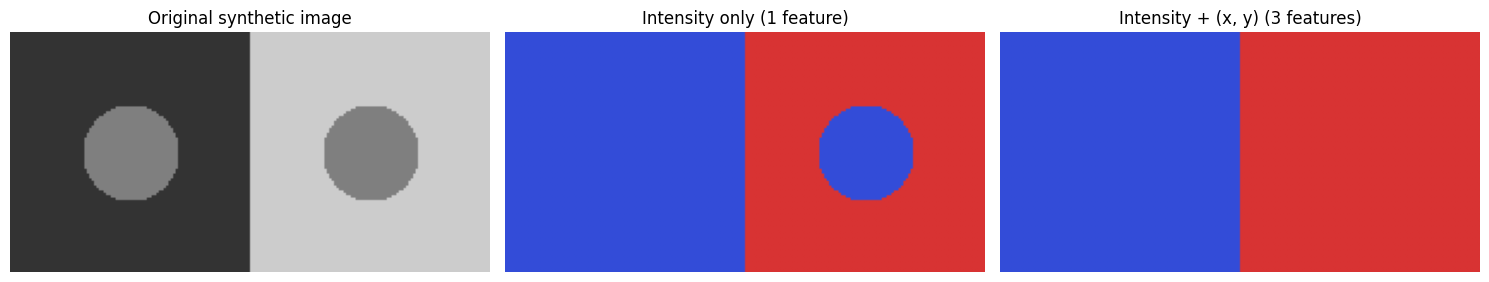

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans

# 1) Build a synthetic image where the same intensity appears in
#    two spatially distant regions.
h, w = 100, 200
yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing='ij')
img_syn = np.zeros((h, w))
img_syn[:, :100] = 0.2   # left background (dark)
img_syn[:, 100:] = 0.8   # right background (bright)

# Two circles with the SAME intensity 0.5, one in each half
left_circle  = (yy - 50) ** 2 + (xx - 50)  ** 2 < 20 ** 2
right_circle = (yy - 50) ** 2 + (xx - 150) ** 2 < 20 ** 2
img_syn[left_circle | right_circle] = 0.5

# 2) K-means with intensity only (1 feature)
X_int = img_syn.reshape(-1, 1)
labels_int = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_int).reshape(h, w)

# 3) K-means with intensity + normalized (x, y) (3 features)
X_sp = np.column_stack([
    img_syn.ravel(),
    xx.ravel() / w,   # x in [0, 1]
    yy.ravel() / h,   # y in [0, 1]
])
labels_sp = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(X_sp).reshape(h, w)

# 4) Visualization using distinct label colours (not cluster centres)
colors = np.array([[0.85, 0.20, 0.20],   # colour 0 (red)
                   [0.20, 0.30, 0.85]])  # colour 1 (blue)

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_syn, cmap='gray', vmin=0, vmax=1)
axes[0].set_title('Original synthetic image')
axes[0].axis('off')

axes[1].imshow(colors[labels_int])
axes[1].set_title('Intensity only (1 feature)')
axes[1].axis('off')

axes[2].imshow(colors[labels_sp])
axes[2].set_title('Intensity + (x, y) (3 features)')
axes[2].axis('off')

plt.tight_layout()
plt.show()

## Application: superpixels

### A superpixel example with the built-in SLIC implementation

`skimage` provides SLIC out of the box. To keep the demonstration fast while
still showing the characteristic shape of superpixels, the input photograph is
first **downscaled to half of its original size** (512×512 → 256×256). The
algorithm is then applied to this smaller image.

SLIC works by running a *local* K-means over 5-dimensional feature vectors that
combine three colour components (in the perceptually uniform Lab space) with
the two pixel coordinates `(x, y)`. Restricting each update to a small window
around every centre is what makes the regions compact and roughly grid-like.
The `compactness` parameter plays the role of the weight `m` on the spatial
term: larger values make the superpixels more regular; smaller values let the
colour term dominate and let regions follow colour boundaries more freely.

image shape after rescaling: (256, 256, 3)


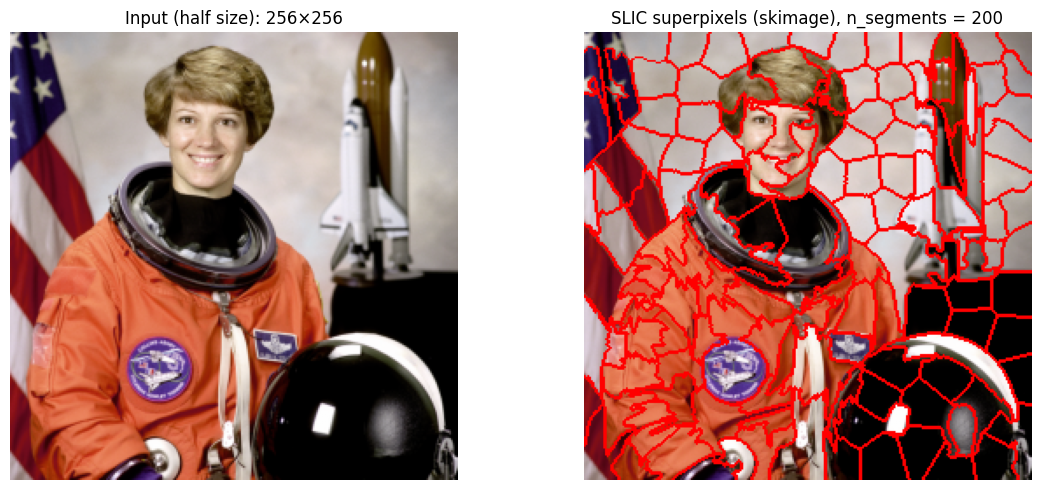

In [7]:
# ============================================================
# Example 2a: SLIC superpixels (skimage) on a half-size image
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from skimage import data, segmentation
from skimage.segmentation import mark_boundaries
from skimage.transform import rescale

# 1) Load the colour photograph and downscale it to half size
image_full = data.astronaut()                  # 512 x 512 RGB
image = rescale(
    image_full,
    scale=0.5,
    channel_axis=-1,
    anti_aliasing=True,
)
print("image shape after rescaling:", image.shape)

# 2) Run the built-in SLIC
segments = segmentation.slic(
    image,
    n_segments=200,        # approximate number of superpixels
    compactness=10,        # balance between colour and space
    start_label=0,
    channel_axis=-1,
)

# 3) Visualise
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title(f'Input (half size): {image.shape[0]}×{image.shape[1]}')
axes[0].axis('off')

axes[1].imshow(mark_boundaries(image, segments, color=(1, 0, 0)))
axes[1].set_title('SLIC superpixels (skimage), n_segments = 200')
axes[1].axis('off')

plt.tight_layout()
plt.show()

### A superpixel-style segmentation with our own K-means

The same idea can be reproduced with nothing more than `KMeans` from
scikit-learn. Each pixel becomes one sample whose features are three Lab colour
components (rescaled to `[0, 1]`) plus the pixel's normalised `(x, y)`
position. The spatial weight controls how strongly the algorithm prefers
nearby pixels over colour similarity.

The resulting regions look less regular than true SLIC because this is a
**global** K-means: it does not restrict assignments to a local window and it
does not perform a connectivity step. It is, however, the same idea, and it
makes clear that the whole trick behind SLIC is simply *"treat the pixel
coordinates as extra features and cluster the 5-D vectors"*.

The input image is downscaled to half its original size so that the runtime on
a 65,536-sample problem stays reasonable while the visual result is still
informative.

image shape after rescaling: (256, 256, 3)


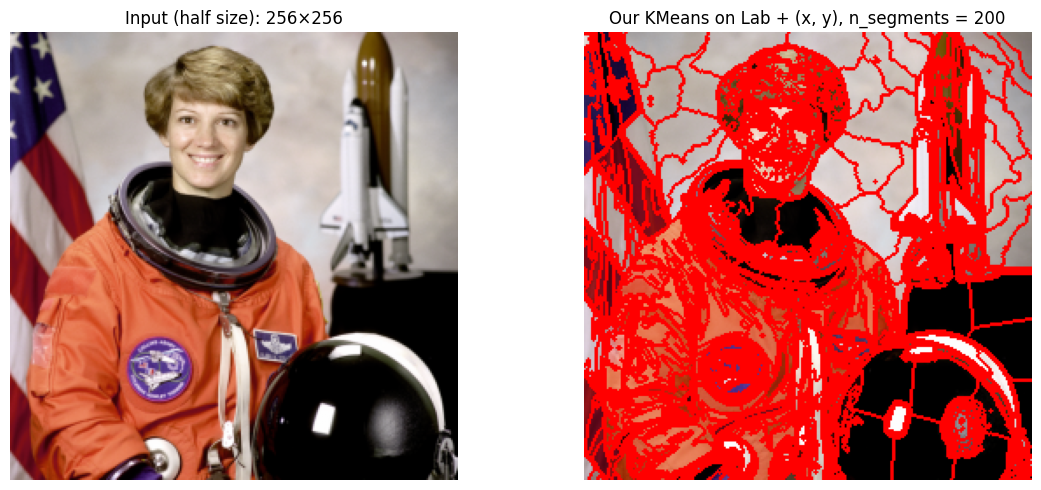

In [8]:
# ============================================================
# Example 2b: superpixel-style segmentation with plain KMeans
#             on a half-size image
# ============================================================
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from skimage import data, color
from skimage.segmentation import mark_boundaries
from skimage.transform import rescale

# 1) Load the colour photograph and downscale it to half size
image_full = data.astronaut()                  # 512 x 512 RGB
image = rescale(
    image_full,
    scale=0.5,
    channel_axis=-1,
    anti_aliasing=True,
)
print("image shape after rescaling:", image.shape)

# 2) Build the 5-D feature matrix: (L, a, b, x, y)
lab = color.rgb2lab(image)
h, w = image.shape[:2]
yy, xx = np.meshgrid(np.arange(h), np.arange(w), indexing='ij')

# Scale colour channels to roughly [0, 1] so that neither
# the colour nor the position term dominates the distance.
spatial_weight = 0.4

features = np.column_stack([
    lab[..., 0].ravel() / 100.0,           # L / 100
    (lab[..., 1].ravel() + 128) / 255.0,   # a in [0, 1]
    (lab[..., 2].ravel() + 128) / 255.0,   # b in [0, 1]
    spatial_weight * xx.ravel() / w,       # normalised x
    spatial_weight * yy.ravel() / h,       # normalised y
])

# 3) Global K-means over the 5-D features
n_segments = 200
kmeans = KMeans(n_clusters=n_segments, n_init=10, random_state=0)
labels = kmeans.fit_predict(features).reshape(h, w)

# 4) Visualise
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(image)
axes[0].set_title(f'Input (half size): {h}×{w}')
axes[0].axis('off')

axes[1].imshow(mark_boundaries(image, labels, color=(1, 0, 0)))
axes[1].set_title('Our KMeans on Lab + (x, y), n_segments = 200')
axes[1].axis('off')

plt.tight_layout()
plt.show()

The difference you see is not a bug: it is the exact reason why SLIC is described as a local variant of K-means. Restricting the search to a window around each centre and enforcing connectivity afterwards are the two ingredients that turn a global K-means into a proper superpixel algorithm.

## 6. The three methods side by side

| method | feature vector of a pixel | what it can separate | what it cannot |
|---|---|---|---|
| thresholding | — (a cut on `v`) | two brightness levels | anything else; needs a hand-set cut |
| K-means on `v` | `(v)` | `K` brightness levels, learned | regions of equal brightness in different places |
| K-means on `(v, x, y)` | `(v, x, y)` | brightness **and** spatial compactness | objects that are not compact; needs a scale weight |

The order of the table is the story of the page. Each row adds one piece of
information that the row above it could not see: the first has no learned
parameters at all, the second learns the levels, the third learns the levels and
uses where the pixels are.

None of them knows what a cup is. What changes is only the *representation* of a
pixel — one number, or three — and the segmentation is whatever the clustering of
that representation produces.

## Summary

* Segmentation assigns a label to each pixel; it is a description of the image,
  not a change to it.
* Thresholding is a hand-set cut on the gray level: correct on a toy array,
  fragile under uneven lighting, and blind beyond two regions.
* `KMeans` wants `(n_samples, n_features)`. For an image that means
  `img.reshape(-1, 1)` — one pixel per row — never the raw `H x W` array, which is
  read as `H` samples with `W` features.
* `labels_` are arbitrary names; `cluster_centers_[labels]` paints the picture with
  real gray levels and makes the result comparable.
* Labels always come back flat and in row-major order, so `reshape(img.shape)` puts
  them on the right pixels.
* Adding `(x, y)` as features lets the clustering use position, which removes
  scattered islands and follows object outlines; the columns must be scaled to a
  common range first, and that scale is the weight of the spatial term.
* Cluster ids must be reordered (here by mean brightness) before two segmentations
  can be compared.

## Exercises

1. Change the threshold in section 2 from `5` to `6` and to `4`. Which pixels
   change region, and what would a "correct" answer even mean on this toy array?
2. Cluster the **colour** image: use `coffee.reshape(-1, 3)` and `K = 8`, then
   paint each pixel with `cluster_centers_[labels]` reshaped back to `(H, W, 3)`.
   Where does colour succeed and gray fail?
3. For the coffee cup, run the intensity-only segmentation with `K = 2, 4, 8, 16`
   and describe what each extra cluster buys. When does the result stop being a
   segmentation and become a shade reduction?
4. Change `K` to `4` in the coordinates experiment while keeping the
   normalisation, and then repeat it with the coordinate columns multiplied by
   `0.2`. Explain the difference in terms of the two distance terms.
5. Plot the inertia (`kmeans.inertia_`) against `K` for `K = 1..10` on the gray
   image. Is there an elbow, and does it agree with the `K` you would choose by
   eye?

## Sources

* The K-means algorithm and its use for image segmentation: {cite}`zaki2020data`.
* `skimage.data.coffee` and `rgb2gray`: the
  [scikit-image data](https://scikit-image.org/docs/stable/api/skimage.data.html)
  and [colour conversion](https://scikit-image.org/docs/stable/api/skimage.color.html)
  documentation.
* The thresholding example follows the
  [scikit-image segmentation walkthrough](https://www.geeksforgeeks.org/image-segmentation-using-pythons-scikit-image-module/).